In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal

In [33]:
df = pd.read_csv("emg_distal_proximal_data.csv")

# tiempo relativo (más fácil de interpretar)
df["timestamp"] = df["timestamp"] - df["timestamp"].iloc[0]
df["emgd_smooth"] = df["emg_distal"].rolling(250).mean()
df["emgd_smooth"] -= df["emgd_smooth"].min()

df["emgp_smooth"] = df["emg_proximal"].rolling(250).mean()
df["emgp_smooth"] -= df["emgp_smooth"].min()

df["y_smooth"] = df["y"].rolling(250).mean()
df["y_smooth"] -= df["y_smooth"].max()
df["y_smooth"] *= -0.01

print(len(df))
df.head()

22625


,timestamp,x,y,emg_distal,emg_proximal,emgd_smooth,emgp_smooth,y_smooth
0,0.000000,521,508,506,508,NaN,NaN,NaN
1,0.002043,521,508,505,507,NaN,NaN,NaN
2,0.002325,521,507,504,504,NaN,NaN,NaN
3,0.004802,521,508,504,502,NaN,NaN,NaN
4,0.007410,521,508,505,499,NaN,NaN,NaN


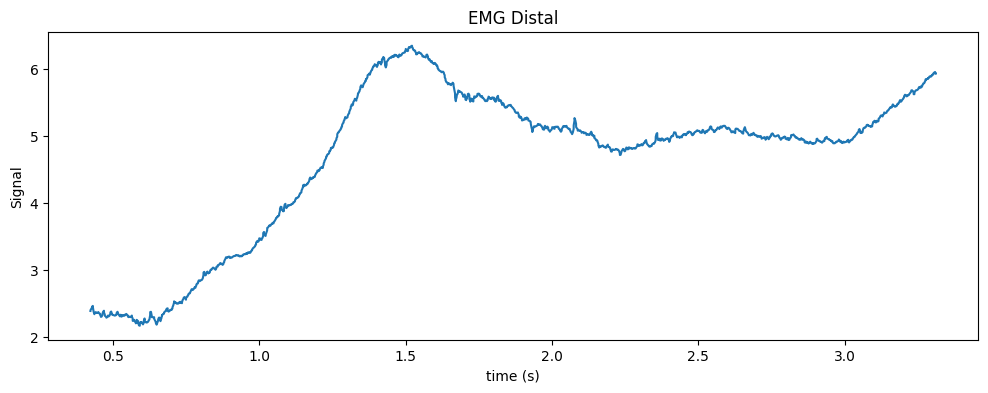

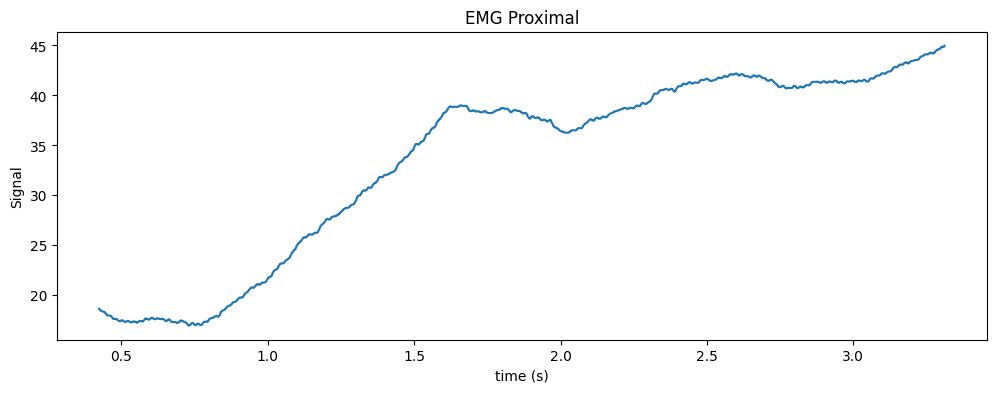

In [34]:
def plot_signal(t, signal, title):
    plt.figure(figsize=(12,4))
    plt.plot(t, signal)
    plt.xlabel("time (s)")
    plt.ylabel("Signal")
    plt.title(title)
    plt.show()    

def plot_emg_vs_joystick(t, emg, y):
    plt.figure(figsize=(12,4))
    plt.plot(t, emg)
    plt.plot(t, y)
    plt.xlabel("time (s)")
    plt.title("Smoothed EMG")
    plt.show()

def plot_frequencies(signal, fs, center=False, title=""):
    if center:
        signal = signal - np.mean(signal)

    N = len(signal)

    fft_vals = np.fft.rfft(signal)
    freqs = np.fft.rfftfreq(N, 1/fs)
    
    magnitude = np.abs(fft_vals)
    
    plt.figure(figsize=(10,5))
    plt.plot(freqs, magnitude)
    
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    if title:
        plt.title(title)
    else:
        plt.title("Signal Frequency Spectrum")
    
    plt.xlim(0, 400)
    plt.grid()
    
    plt.show()
    
plot_signal(df["timestamp"][20:2000], df["emgd_smooth"][20:2000], "EMG Distal")
plot_signal(df["timestamp"][20:2000], df["emgp_smooth"][20:2000], "EMG Proximal")

In [35]:
# La señal es ruidosa, vamos a ver cual es la frecuencia correspondiente haciendo análisis de fourier para entender 
# cual es la fuente del ruido
dt = np.diff(df["timestamp"])
fs = 1 / np.mean(dt)

print("Sampling frequency:", fs, "Hz")
print("Sampling Standard Deviation:", dt.std(), "Hz")

Sampling frequency: 624.3181216619703 Hz
Sampling Standard Deviation: 0.0011482721017462224 Hz


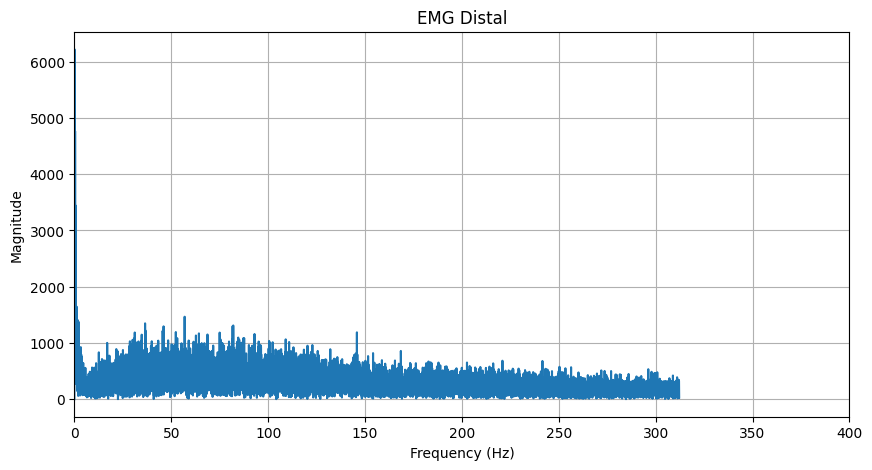

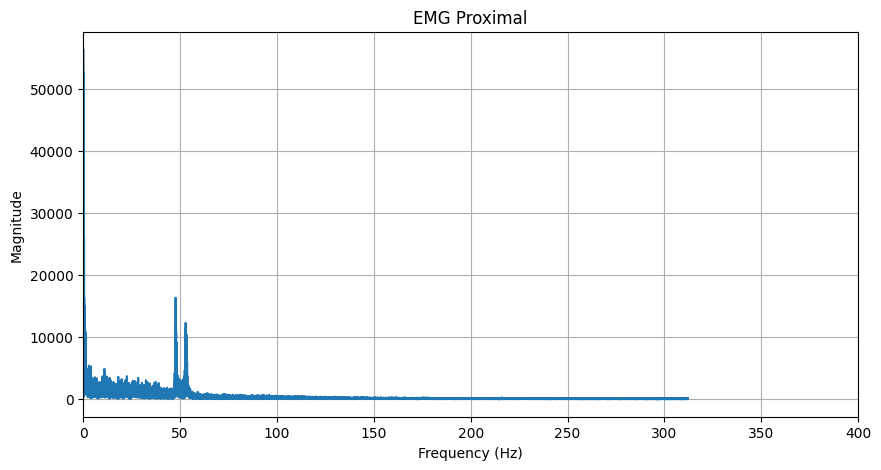

In [36]:
emg = df["emg_distal"].values
plot_frequencies(emg, fs, center=True, title="EMG Distal")

emg = df["emg_proximal"].values
plot_frequencies(emg, fs, center=True, title="EMG Proximal")

In [46]:
print(df["emg_distal"].corr(df["y"]))
print(df["emg_proximal"].corr(df["y"]))

-0.016283174950956256
-0.1085398244422105


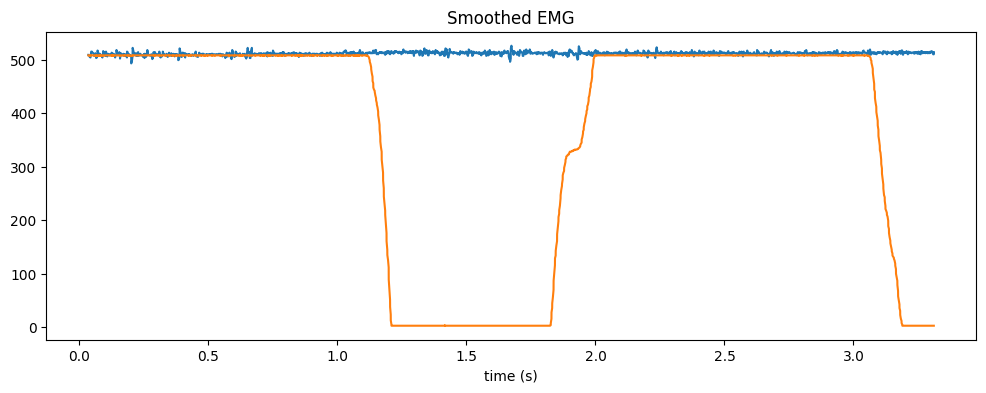

In [47]:
plot_emg_vs_joystick(df["timestamp"][20:2000], df["emg_distal"][20:2000], df["y"][20:2000])

In [49]:
def apply_notch_filter(emg, f0, Q, fs):
    b_notch, a_notch = signal.iirnotch(f0, Q, fs)
    return signal.filtfilt(b_notch, a_notch, emg)

-0.10908135459533425


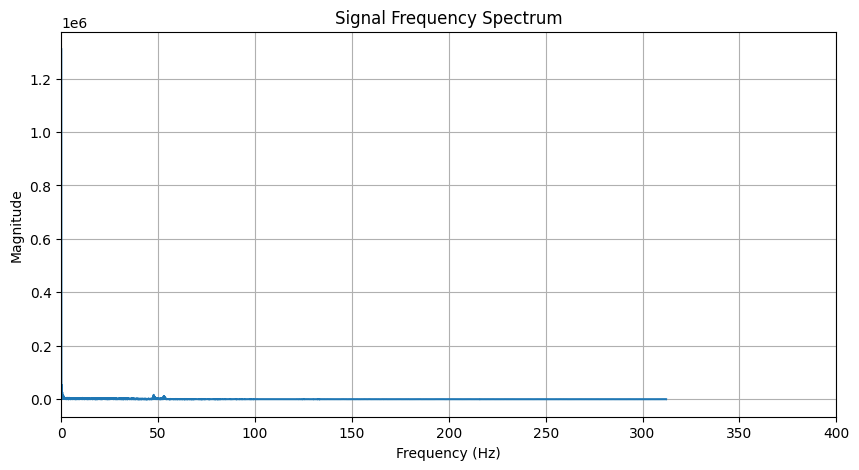

In [73]:
# Apply notch filters to remove that noise
emg = df["emg_proximal"]
emg = emg - emg.min()


def apply_notch_filter(emg, f0, Q, fs):
    b_notch, a_notch = signal.iirnotch(f0, Q, fs)
    return signal.filtfilt(b_notch, a_notch, emg)
    
emg = apply_notch_filter(emg, 55, 50, fs)

df["emgp_notched"] = emg
print(df["emgp_notched"].corr(df["y"]))
plot_frequencies(df["emgp_notched"], fs, center=False)

-0.16615712114205505


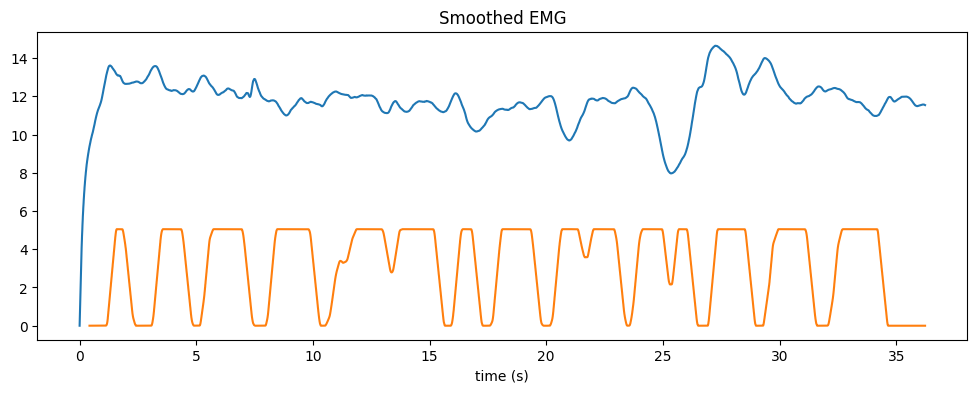

0.08126370979560593


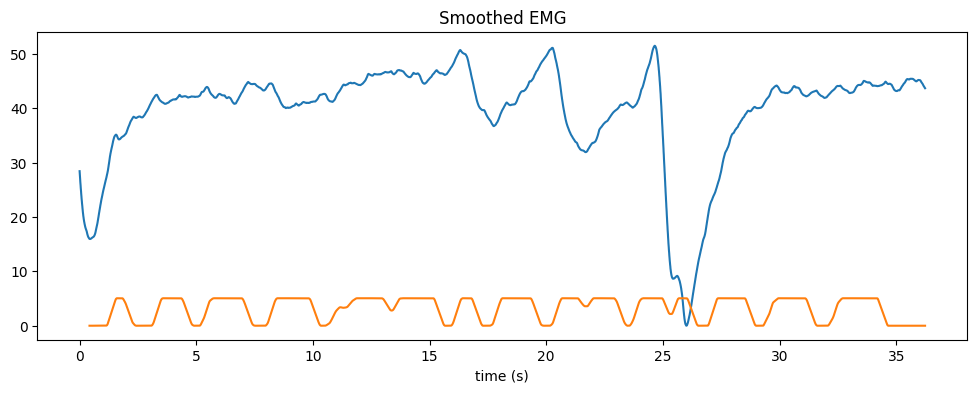

In [74]:
b_env, a_env = signal.butter(1, 1, btype="low", fs=fs)
emg_env = signal.filtfilt(b_env, a_env, df["emg_distal"])
df["emgd_env"] = emg_env - emg_env.min()

print(df["emgd_env"].corr(df["y_smooth"]))
plot_emg_vs_joystick(df["timestamp"], df["emgd_env"], df["y_smooth"])

b_env, a_env = signal.butter(1, 1, btype="low", fs=fs)
emg_env = signal.filtfilt(b_env, a_env, df["emgp_notched"])
df["emgp_env"] = emg_env - emg_env.min()

print(df["emgp_env"].corr(df["y_smooth"]))
plot_emg_vs_joystick(df["timestamp"], df["emgp_env"], df["y_smooth"])

The correlation got a little bit smaller but the signal smoother and it clearly anticipates 
the movement of the joystick in direction and amplitude which is great for trainning a Neural Network for control 

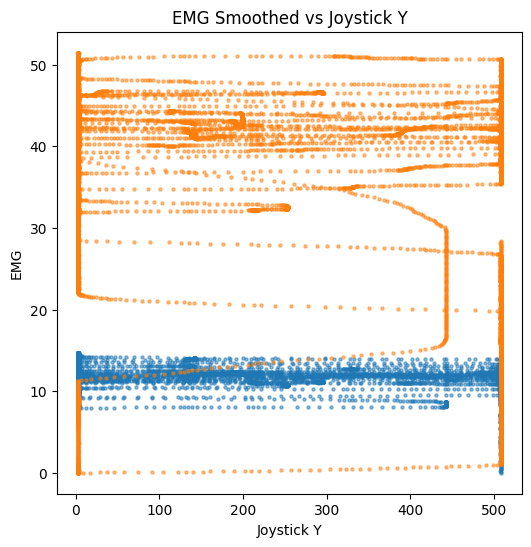

In [76]:
plt.figure(figsize=(6,6))
plt.scatter(df["y"], df["emgd_env"], s=5, alpha=0.5)
plt.scatter(df["y"], df["emgp_env"], s=5, alpha=0.5)
plt.xlabel("Joystick Y")
plt.ylabel("EMG")
plt.title("EMG Smoothed vs Joystick Y")
plt.show()